(saving-loading-models)=
# Saving and Loading Models

### Model Persistence

GAMLSS models can be saved and loaded for later use, enabling reproducible analysis and model deployment across sessions.

### gamlss_main.Gamlss.<br>**save_model**

```python
save_model(file_path)
```

&nbsp;&nbsp;&nbsp;&nbsp;Uses R's `saveRDS` function to save the complete GAMLSS model object, including all fitted parameters, formulas, and metadata. The saved model can be loaded in future sessions.

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**Parameters:**</span>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**file_path** : ***str*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Path where the model will be saved (.rds extension added automatically)

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**Returns:**</span>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**None** : ***None*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Saves the model to the specified file path

<br>

**Examples:**

In [21]:
import os

from normgamlss.gamlss_main import Gamlss

# Save the fitted model (the folder must exist)
os.makedirs("../../results", exist_ok=True)
gamlss_model.save_model("../../results/my_gamlss_model.rds")

Model saved to ../../results/my_gamlss_model.rds


### gamlss_main.Gamlss.<br>**load_model** (class method)

```python
load_model(file_path)
```

&nbsp;&nbsp;&nbsp;&nbsp;Loads a previously saved GAMLSS model using R's `readRDS` function. Automatically extracts model metadata including variable names and formulas to recreate the Python wrapper.

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**Parameters:**</span>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**file_path** : ***str*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Path to the saved model file

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**Returns:**</span>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**model** : ***Gamlss*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;New Gamlss instance with the loaded model

<br>


**Examples:**

In [22]:
# Load a previously saved model
loaded_model = Gamlss.load_model("../../results/my_gamlss_model.rds")

Model 'model_shash_2' loaded from ../../results/my_gamlss_model.rds


In [23]:
# Verify the loaded model works
z_scores = loaded_model.z_score(df_test, df_train)
print('Loaded model Z-scores:', z_scores[:5])


Loaded model Z-scores: [ 0.16719671  3.25534027 -1.32695918  0.78290266  1.13964224]


### Sharing a model without the training data (slim models)

**Why does prediction need the training data?** Each parameter of the model is a sum of parts, for example

$$\mu = \beta_0 + \beta_{\text{sex}} + f(\text{age}) + u_{\text{site}}$$

The numbers ($\beta$ and the site effects $u$) are stored in the fitted model. The smooth age curve $f$ is not stored as numbers: gamlss keeps it as a recipe and rebuilds it from the training data every time it predicts for new people. That is why `predict_all`, `z_score`, `centiles` and the plots ask for `train_data`, and why a model saved with `save_model` is only useful together with its training data. The saved file also holds every training participant's outcome and fitted values, so it often cannot be shared.

**How a slim model gets around it.** `export_slim` does the rebuilding once, while you still have the training data: it writes down the value of each smooth curve every 0.01 years of age (separately per group, e.g. per sex), next to the coefficients, site effects, link functions and family. Predicting is then looking up the curve at the new ages. The file holds no row of the training data, and it is much smaller.

**How close is it?** The slim model gives the same predictions up to tiny differences. On large real-data models (about 21,000 people) the z-scores differed by at most 0.0003, the file was 149 KB instead of 81 MB, and predictions were about 10 times faster. If a fitted model's own parts do not add up exactly (for example when it has not fully converged), `export_slim` warns you, and the two can differ a little more.

**What works and what does not.** Everything that predicts works with `train_data=None`: `predict_all`, `z_score`, `centiles`, `get_centile_position`, `evaluate`, the centile and z-score plots, `create_site_adjusted_data` and site transfer. What needs the training rows does not: residuals, fitted values and the diagnostic plots (QQ, worm plots) give a clear error, so keep the full model for those. Ages outside the training range are extrapolated linearly, with a warning.

Models saved by `save_model()` or by the pipelines (`save_models=True`) are full models. To share one, load it and export a slim copy with its training data, as below.

### gamlss_main.Gamlss.<br>**export_slim**

```python
export_slim(train_data, file_path, grid_step=0.01)
```

&nbsp;&nbsp;&nbsp;&nbsp;Writes a slim, data-free copy of the model. Load it with `load_model()`: it loads as `'<model_name>_slim'`, next to the full model if that is loaded too.

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**Parameters:**</span>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**train_data** : ***pandas.DataFrame*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;The data the model was fitted on (used for the export and its self-check; none of it is stored)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**file_path** : ***str*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Where to write the slim model (.rds extension added automatically)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**grid_step** : ***float***, *default=0.01* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Spacing of the grid on which the smooth curves are stored (in units of the continuous variable, e.g. years)

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**Returns:**</span>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**check** : ***dict*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Self-check: for each parameter, the largest difference between the rebuilt and the fitted linear predictor on the training rows

<br>

**Examples:**

In [24]:
# Write a slim copy, once, with the data the model was fitted on
check = gamlss_model.export_slim(df_train, "../../results/my_gamlss_model_slim.rds")
print('Self-check (largest difference per parameter):', check)

Self-check (largest difference per parameter): {'mu': 6.394884621840902e-13, 'sigma': 4.263256414560601e-14, 'nu': 1.3367085216486885e-13, 'tau': 5.071498776487715e-13}


In [25]:
# Load the slim copy and use it WITHOUT the training data (train_data=None)
slim_model = Gamlss.load_model("../../results/my_gamlss_model_slim.rds")

z_slim = slim_model.z_score(df_test, None)
z_full = gamlss_model.z_score(df_test, df_train)
print('Slim model Z-scores:', z_slim[:5])
print('Largest difference from the full model:', np.max(np.abs(z_slim - z_full)))

Model 'model_shash_slim' loaded from ../../results/my_gamlss_model_slim.rds
Slim model Z-scores: [ 0.16719627  3.25533195 -1.3269772   0.78291461  1.13963571]
Largest difference from the full model: 0.0001287406076357911


site: user specified = HJDXM


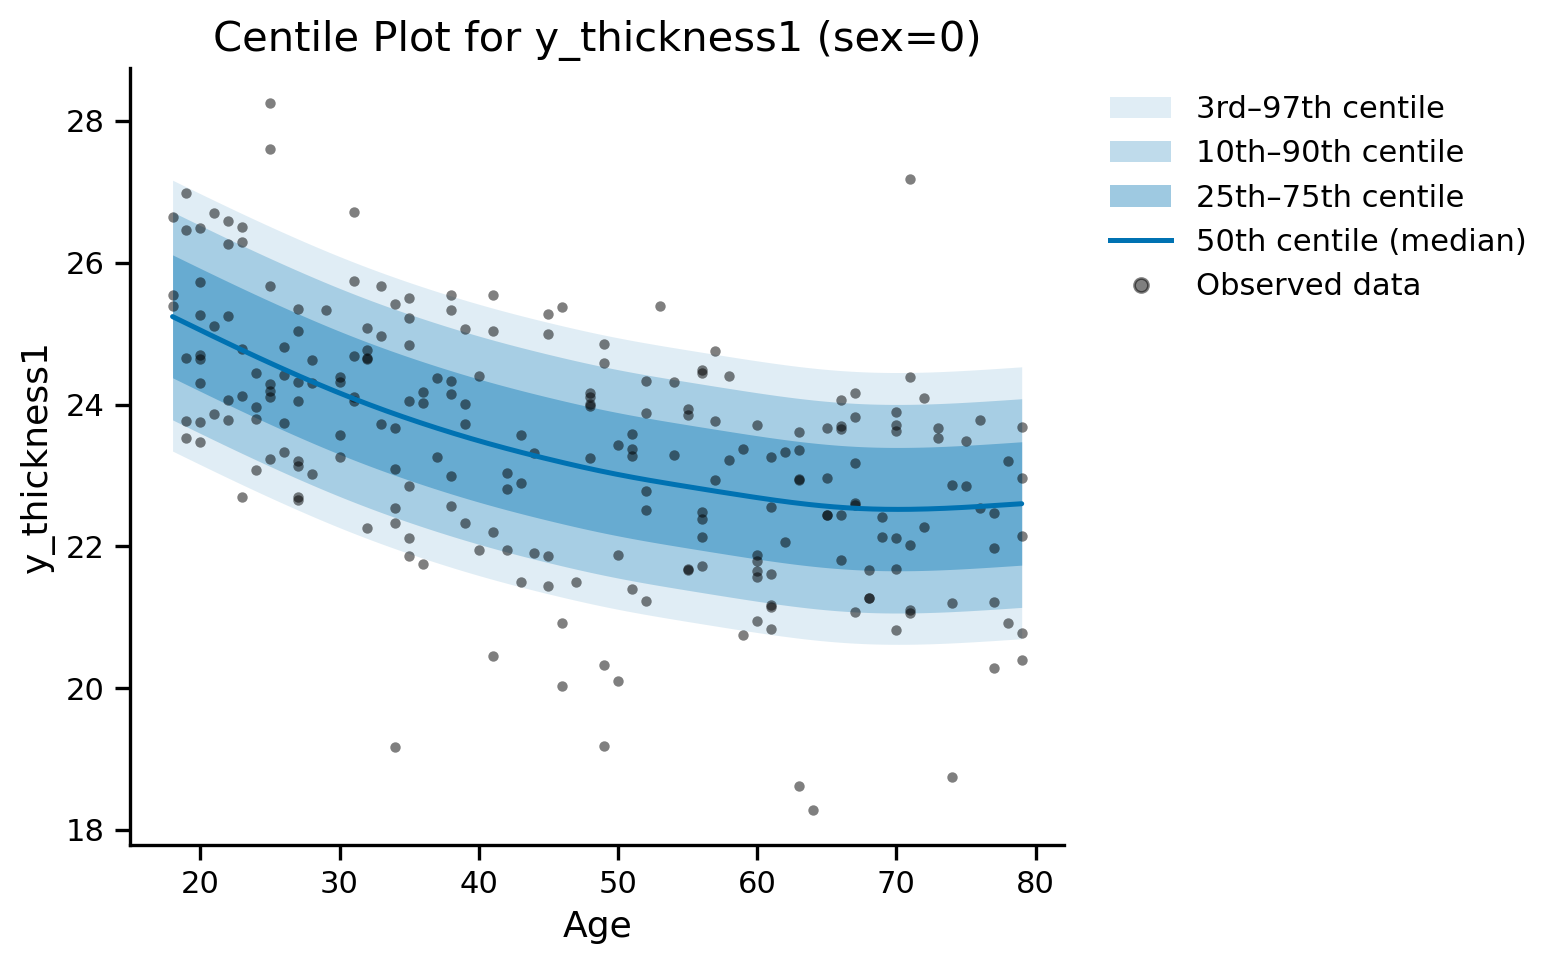


Values used for centile calculation in this plot:
sex: 0
site: HJDXM

Scatter data filtered by:
  variables_to_split:
    sex: 0


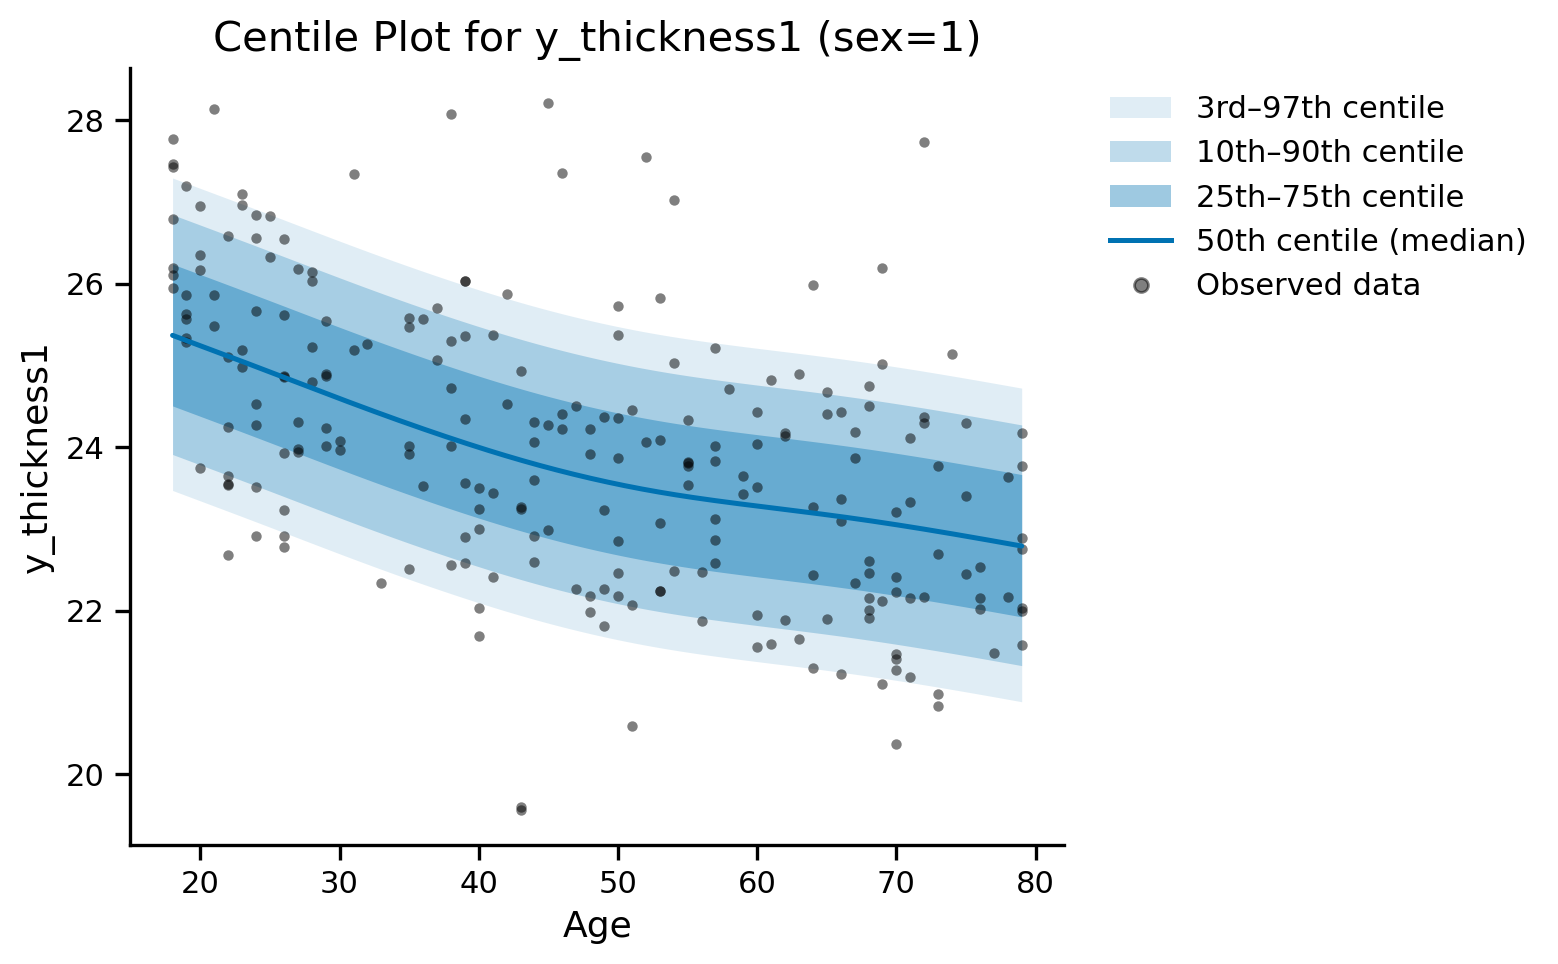


Values used for centile calculation in this plot:
sex: 1
site: HJDXM

Scatter data filtered by:
  variables_to_split:
    sex: 1


In [26]:
# Plots work the same way
slim_model.plot_centiles(df_test, None, centiles=[3, 10, 25, 50, 75, 90, 97],
                         variables_to_split={'sex': [0, 1]}, additional_global_vars={'site': 'HJDXM'},
                         x_axis={'age': 'Age'}, plot_scatter=True, figsize=(8, 5));